# Evaluating RAG and Agent Performance with RAGAS

In [25]:
#!pip install ragas
#!pip install -U langchain-community
#!pip install -U langchain-google-vertexai

from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, AIMessage
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langgraph.graph import START, END, StateGraph
from langgraph.graph.message import MessagesState
from langgraph.prebuilt import ToolNode
from IPython.display import Image, display
from dotenv import load_dotenv
from ragas import EvaluationDataset
from ragas import evaluate
from ragas.llms import LangchainLLMWrapper

from ragas.metrics.collections import (
    ContextRecall,       # <-- 'LLMContextRecall' is now 'ContextRecall'
    Faithfulness, 
    FactualCorrectness, 
    ToolCallAccuracy, 
    AgentGoalAccuracyWithReference
)
from ragas import messages as ragas_messages
from ragas.integrations.langgraph import convert_to_ragas_messages
from ragas.dataset_schema import MultiTurnSample


# removing dependecy issues with Ragas package
#!sed -i '' "s/from langchain_community.chat_models.vertexai import ChatVertexAI/from langchain_google_vertexai import ChatVertexAI/g" /opt/anaconda3/envs/udemyllms/lib/python3.12/site-packages/ragas/llms/base.py
#!sed -i '' "s/from langchain_community.llms import VertexAI/from langchain_google_vertexai import VertexAI/g" /opt/anaconda3/envs/udemyllms/lib/python3.12/site-packages/ragas/llms/base.py


In [26]:

load_dotenv("/Users/oasis/Udacity AI Masters/Agentic/Code/.env")

True

In [27]:
# SIMPLE RAG DOC

documents = [
    Document(
        page_content="Meta drops multimodal Llama 3.2 — here's why it's such a big deal",
        metadata={"company":"Meta", "topic": "llama"}
    ),
    Document(
        page_content="Chip giant Nvidia acquires OctoAI, a Seattle startup that helps companies run AI models",
        metadata={"company":"Nvidia", "topic": "acquisition"}
    ),
    Document(
        page_content="Google is bringing Gemini to all older Pixel Buds",
        metadata={"company":"Google", "topic": "gemini"}
    ),
    Document(
        page_content="The first Intel Battlmage GPU benchmarks have leaked",
        metadata={"company":"Intel", "topic": "gpu"}
    ),
    Document(
        page_content="Dell partners with Nvidia to accelerate AI adoption in telecoms",
        metadata={"company":"Dell", "topic": "partnership"}
    ),
]

ids = ["id1", "id2", "id3", "id4", "id5"]

In [28]:
vector_store = Chroma(
    collection_name="udacity",
    embedding_function=OpenAIEmbeddings(),
)

vector_store.add_documents(documents=documents, ids=ids)
retriever = vector_store.as_retriever(search_kwargs={"k": 1})

In [29]:
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.0,
)

In [30]:
prompt = ChatPromptTemplate.from_template(
    """Answer the question based only on the following context:
    {context}

    Question: {query}
    """
)

chain = prompt | llm | StrOutputParser()

In [31]:
def format_docs(relevant_docs):
    return "\n".join(doc.page_content for doc in relevant_docs)

query = "Who is partnering with Nvidia?"
relevant_docs = retriever.invoke(query)
chain.invoke({"context": format_docs(relevant_docs), "query": query})

'Dell is partnering with Nvidia.'

# **Ragas Evaluation**

In [33]:
sample_queries = [
    "What is Meta's latest development in AI?",
    "Which company did Nvidia acquire?",
    "What AI feature is Google adding to older Pixel Buds?",
    "What recent information has leaked about Intel GPUs?",
    "Which company did Dell partner with to accelerate AI adoption?"
]

In [34]:
expected_responses = [
    "Meta drops multimodal Llama 3.2 — here's why it's such a big deal",
    "Chip giant Nvidia acquires OctoAI, a Seattle startup that helps companies run AI models",
    "Google is bringing Gemini to all older Pixel Buds",
    "The first Intel Battlemage GPU benchmarks have leaked",
    "Dell partners with Nvidia to accelerate AI adoption in telecoms"
]

In [35]:
dataset = []

for query, reference in zip(sample_queries, expected_responses):
    relevant_docs = retriever.invoke(query)
    response = chain.invoke(
        {
            "context": format_docs(relevant_docs), 
            "query": query
        }
    )
    dataset.append(
        {
            "user_input": query,
            "retrieved_contexts": [doc.page_content for doc in relevant_docs],
            "response": response,
            "reference": reference,
        }
    )

evaluation_dataset = EvaluationDataset.from_list(dataset)

In [48]:
from ragas import evaluate
from ragas.llms import LangchainLLMWrapper
# Import from legacy paths to make evaluate() happy
from ragas.metrics import faithfulness, answer_correctness, context_recall

# You can go back to using your original LangchainLLMWrapper here
evaluator_llm = LangchainLLMWrapper(llm)

result = evaluate(
    dataset=evaluation_dataset,
    metrics=[context_recall, faithfulness, answer_correctness],
    llm=evaluator_llm
)

print(result)


/var/folders/ws/1hfjcgys5mx889l7xsvl7zpw0000gn/T/ipykernel_30102/3543753254.py:4: DeprecationWarning: Importing faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import faithfulness
  from ragas.metrics import faithfulness, answer_correctness, context_recall
/var/folders/ws/1hfjcgys5mx889l7xsvl7zpw0000gn/T/ipykernel_30102/3543753254.py:4: DeprecationWarning: Importing answer_correctness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import answer_correctness
  from ragas.metrics import faithfulness, answer_correctness, context_recall
/var/folders/ws/1hfjcgys5mx889l7xsvl7zpw0000gn/T/ipykernel_30102/3543753254.py:4: DeprecationWarning: Importing context_recall from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. E

Evaluating: 100%|██████████| 15/15 [00:06<00:00,  2.34it/s]

{'context_recall': 1.0000, 'faithfulness': 1.0000, 'answer_correctness': 0.7391}


In [49]:
result

{'context_recall': 1.0000, 'faithfulness': 1.0000, 'answer_correctness': 0.7391}

# **Evaluation using LangGraph workflow**

In [50]:
pokemon_types_map = {
    "pikachu": "electric",
    "eevee": "normal",
    "bulbasaur": "grass/poison",
    "squirtle": "water",
    "charizard": "fire/flying",
    "jigglypuff": "normal/fairy",
    "meowth": "normal",
    "psyduck": "water",
    "machamp": "fighting",
    "gengar": "ghost/poison",
    "alakazam": "psychic",
    "snorlax": "normal",
    "dragonite": "dragon/flying",
}

In [51]:
@tool
def get_pokemon_type(pokemon_name: str) -> str:
    """Fetches the type of the specified Pokémon.

    Args:
        pokemon_name : The name of the Pokémon (e.g., 'pikachu', 'charizard', 'eevee').

    Returns:
        str: The type(s) of the Pokémon.

    Raises:
        KeyError: If the specified Pokémon is not found in the data source.
    """
    try:
        pokemon_name = pokemon_name.lower().strip()
        if pokemon_name not in pokemon_types_map:
            raise KeyError(
                f"Pokémon '{pokemon_name}' not found. Available Pokémon: {', '.join(pokemon_types.keys())}"
            )
        return pokemon_types_map[pokemon_name]
    except Exception as e:
        raise Exception(f"Error fetching Pokémon type: {str(e)}")

In [52]:
tools = [get_pokemon_type]

In [53]:
llm_with_tools = llm.bind_tools(tools)


In [54]:
def agent(state: MessagesState):
    ai_message = llm_with_tools.invoke(state["messages"])
    return {"messages": ai_message}

In [55]:
def router(state: MessagesState):
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "tools"

    return END

In [56]:
workflow = StateGraph(MessagesState)

workflow.add_node("agent", agent)
workflow.add_node("tools", ToolNode(tools))

workflow.add_edge(START, "agent")

workflow.add_conditional_edges(
    source="agent", 
    path=router, 
    path_map=["tools", END]
)

workflow.add_edge("tools", "agent")


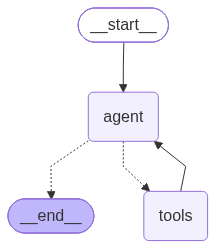

In [57]:
graph = workflow.compile()

display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

In [58]:
result = graph.invoke(
    {"messages": [HumanMessage(content="What is the Gengar's type?")]}
)

In [60]:
# Converting to Ragas
ragas_trace = convert_to_ragas_messages(result["messages"])

In [94]:
ragas_trace

[HumanMessage(content='What type of Pokemon is Gengar?', additional_kwargs={}, response_metadata={}),
 AIMessage(content='', additional_kwargs={}, response_metadata={}, tool_calls=[{'name': 'get_pokemon_type', 'args': {'pokemon_name': 'gengar'}, 'id': 'call_1', 'type': 'tool_call'}], invalid_tool_calls=[]),
 ToolMessage(content='Gengar is a Ghost/Poison type Pokemon.', tool_call_id='call_1'),
 AIMessage(content='Gengar is a Ghost/Poison type Pokemon.', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]

In [102]:
from ragas.messages import HumanMessage, AIMessage, ToolMessage, ToolCall
from ragas.dataset_schema import MultiTurnSample

ragas_user_input = []

for msg in ragas_trace:
    if msg.type == 'human':
        ragas_user_input.append(HumanMessage(content=msg.content))
        
    elif msg.type == 'ai':
        ragas_tools = []
        # LangChain stores tool calls as a list of dictionaries on the AIMessage
        if hasattr(msg, 'tool_calls') and msg.tool_calls:
            for tc in msg.tool_calls:
                # Map LangChain's dictionary to Ragas's ToolCall object
                ragas_tools.append(ToolCall(name=tc['name'], args=tc['args']))
                
        ragas_user_input.append(AIMessage(
            content=msg.content if msg.content else "",
            tool_calls=ragas_tools if ragas_tools else None
        ))
        
    elif msg.type == 'tool':
        ragas_user_input.append(ToolMessage(content=msg.content))

# Pass the updated list to MultiTurnSample
sample = MultiTurnSample(
    user_input=ragas_user_input,
    reference_tool_calls=[
        ragas_messages.ToolCall(
            name="get_pokemon_type", 
            args={"pokemon_name": "gengar"}
        )
    ]
)

In [103]:
scorer = ToolCallAccuracy()
scorer.llm = llm

In [104]:
# Pass the data as keyword arguments to ascore()
result = await scorer.ascore(
    user_input=sample.user_input,
    reference_tool_calls=sample.reference_tool_calls
)

# Extract the float score from the MetricResult object
print(f"Tool Call Accuracy Score: {result.value}")

Tool Call Accuracy Score: 1.0


In [112]:
# Evaluate


sample = MultiTurnSample(
    user_input=ragas_user_input, 
    reference="What is the Gengar's type?",
)

In [128]:
import os
from openai import AsyncOpenAI
from ragas.llms import llm_factory
from ragas.messages import HumanMessage, AIMessage, ToolMessage, ToolCall
from ragas.dataset_schema import MultiTurnSample
from ragas.metrics.collections import AgentGoalAccuracyWithReference

# =====================================================================
# 1. CONVERT LANGCHAIN TRACE TO RAGAS MESSAGES
# =====================================================================
ragas_user_input = []

for msg in ragas_trace:
    if msg.type == 'human':
        ragas_user_input.append(HumanMessage(content=msg.content))
        
    elif msg.type == 'ai':
        ragas_tools = []
        if hasattr(msg, 'tool_calls') and msg.tool_calls:
            for tc in msg.tool_calls:
                ragas_tools.append(ToolCall(name=tc['name'], args=tc['args']))
                
        ragas_user_input.append(AIMessage(
            content=msg.content if msg.content else "",
            tool_calls=ragas_tools if ragas_tools else None
        ))
        
    elif msg.type == 'tool':
        ragas_user_input.append(ToolMessage(content=msg.content))


# =====================================================================
# 2. CREATE MULTI-TURN SAMPLE
# =====================================================================
sample = MultiTurnSample(
    user_input=ragas_user_input,
    reference="What is Gengar's type?",
)


# =====================================================================
# 3. INITIALIZE EVALUATOR LLM (ASYNC CLIENT)
# =====================================================================
client = AsyncOpenAI(api_key=os.environ.get("OPENAI_API_KEY"))
eval_llm = llm_factory("gpt-4o-mini", client=client)

scorer = AgentGoalAccuracyWithReference(llm=eval_llm)


# =====================================================================
# 4. RUN EVALUATION
# =====================================================================
result = await scorer.ascore(
    user_input=sample.user_input,
    reference=sample.reference
)

print(f"Goal Accuracy Score: {result.value}")

Goal Accuracy Score: 1.0
